In [7]:

r_path <- "/notebooks/Bioinformatics/lib/"
.libPaths(c(r_path, .libPaths()))

# Load required packages
library(limma)
library(piano)
library(randomForest)
library(ggplot2) # Optional - for plotting


In [8]:
# 1. Drug combination response prediction ---------------------------------

# Read drug combination response data from data/drug_combination_responses.csv
data <- read.csv("../data/ex3/drug_combination_responses.csv")

# Hint: factor() and model.matrix() for one-hot encoding
drug_1_type <- factor(data$drug_1)
drug_2_type <- factor(data$drug_2)
drug_1_concentration_fac <- factor(data$drug_1_concentration)
drug_2_concentration_fac <- factor(data$drug_2_concentration)
cell_line_type <- factor(data$cell_line)
df <- data.frame(drug_1 = drug_1_type,
                 drug_2 = drug_2_type,
                 drug_1_concentration = drug_1_concentration_fac,
                 drug_2_concentration = drug_2_concentration_fac,
                 cell_line = cell_line_type)
f <- formula("~ -1 + drug_1 + drug_2 + drug_1_concentration + drug_2_concentration + cell_line")
model <- model.matrix(f, df)
model_cell_type <- model.matrix(~ -1 + cell_line, df)

# Training-test set splits
# 1st set - whole dataset
# Set random and size
set.seed(123)
n <- nrow(model)
idx <- sample(seq_len(n), size = 0.8 * n)

x_train_1 <- model[idx, ]
x_test_1  <- model[-idx, ]
y_train_1 <- data$response[idx]
y_test_1  <- data$response[-idx]

# 2nd set - based on unique cell line types (80% of cell lines for training, 
#           all their observations, test on remaining 20% of cell lines)
set.seed(100)
# Get unique cell lines
unique_cell_lines <- unique(data$cell_line)
n_cell_lines <- length(unique_cell_lines)
# Select 80% of cell lines for training
n_train_cell_lines <- floor(0.8 * n_cell_lines)
train_cell_lines <- sample(unique_cell_lines, size = n_train_cell_lines)
# Create indices for training and test sets based on cell lines
train_idx <- which(data$cell_line %in% train_cell_lines)
test_idx <- which(!data$cell_line %in% train_cell_lines)
# Split the data based on these indices
x_train_2 <- model[train_idx, ]
x_test_2  <- model[test_idx, ]
y_train_2 <- data$response[train_idx]
y_test_2  <- data$response[test_idx]

# Hint: randomForest() and predict() for training and predicting with random forest models
pred_1 <- randomForest(x_train_1, y_train_1, ntree = 500)
y_pred_1 <- predict(pred_1, x_test_1)
pred_2 <- randomForest(x_train_2, y_train_2, ntree = 500)
y_pred_2 <- predict(pred_2, x_test_2)

# Hint: cor() for computing the Pearson correlations on the test sets
cor_1 <- cor(y_test_1, y_pred_1)
cor_2 <- cor(y_test_2, y_pred_2)
message('Pearson correlation coefficients for random split')
cor_1
message('Pearson correlation coefficients for cell line split')
cor_2

Pearson correlation coefficients for random split



[1] 0.9474341

Pearson correlation coefficients for cell line split



[1] 0.755854

Proportion of variance explained by PC1



[1] 9.57

Proportion of variance explained by PC2



[1] 7.73

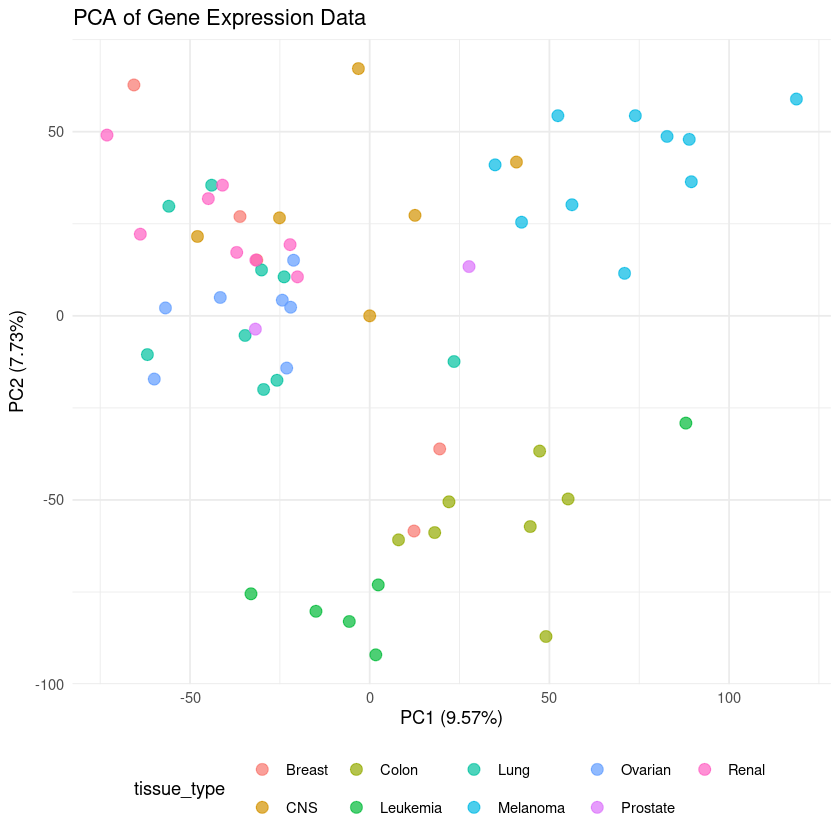

In [9]:
# 2. Gene expression data exploration -------------------------------------


# Read the gene expression data and metadata from data/gene_expression.csv and
# data/cell_line_metadata.csv
data_1 <- read.csv("../data/ex3/gene_expression.csv")
metadata_1 <- read.csv("../data/ex3/cell_line_metadata.csv")

# Cleaning function
cleaning <- function(dataframe){
    for(i in 1:ncol(dataframe)) {
        if(any(is.na(dataframe[, i]))) {
            col_mean <- mean(dataframe[, i], na.rm = TRUE)
            dataframe[is.na(dataframe[, i]), i] <- col_mean
        }
    }
    return(dataframe)
}

data_1_numOnly <- data_1[, -1]
cleaned_data_1 <- cleaning(data_1_numOnly)

# Hint: prcomp() for PCA
pca_data1 <- prcomp(cleaned_data_1, scale. = TRUE, rank. = 2)

# Variances proportion extractions
allVarPro <- pca_data1$sdev^2 / sum(pca_data1$sdev^2)
varPro1 <- allVarPro[1]
varPro2 <- allVarPro[2]

# Create a dataframe for later visualizing
pc_scores <- as.data.frame(pca_data1$x[,1:2])
pc_scores$tissue_type <- metadata_1$tissue_type

# Create scatter plot colored by tissue type
library(ggplot2)

pca_plot <- ggplot(pc_scores, aes(x = PC1, y = PC2, color = tissue_type)) +
    geom_point(size = 3, alpha = 0.7) +
    labs(title = "PCA of Gene Expression Data",
       x = paste0("PC1 (", round(varPro1 * 100, 2), "%)"),
       y = paste0("PC2 (", round(varPro2 * 100, 2), "%)")) +
    theme_minimal() +
    theme(legend.position = "bottom")

# Display the plot
print(pca_plot)

# Print the proportion of variance explained
message("Proportion of variance explained by PC1")
round(varPro1 * 100, 2)
message("Proportion of variance explained by PC2")
round(varPro2 * 100, 2)


In [10]:
# 3-5. Differential gene expression analysis ------------------------------

# For performing the differential gene expression analysis using limma, 
# you can refer to the examples shown in Section 9.2 of the limma user guide:
# https://www.bioconductor.org/packages/devel/bioc/vignettes/limma/inst/doc/usersguide.pdf

In [13]:
# 3 Creating design matrix
# Factor the states
states <- factor(metadata_1$TP53_status)
states <- relevel(states, ref = "Wildtype") 
# Construct design matrix
design <- model.matrix(~ states)
colnames(design) <- c("Intercept", "TP53mut") # renaming for safety reasons
# Make contrast matrix
cont_matrix <- makeContrasts(TP53mut_vs_WT = TP53mut, levels = design)
cont_matrix

,TP53mut_vs_WT
Intercept,0
TP53mut,1


In [14]:
# 4. Differential expression analysis -------------------------------------

# Make the dataframe correct
eset <- t(cleaned_data_1) 

# Fit linear model
fit <- lmFit(eset, design)

# Apply contrast
fit2 <- contrasts.fit(fit, cont_matrix)

# Empirical Bayes moderation
fit2 <- eBayes(fit2)

# Get results with multiple testing correction (Benjamini-Hochberg)
results <- topTable(fit2, adjust.method = "BH", number = Inf)

# Filter for significant genes (adj.P.Val < 0.05)
sig_genes <- results[results$adj.P.Val < 0.05, ]

# Order by absolute log fold change (most changed first)
sig_genes <- sig_genes[order(abs(sig_genes$logFC), decreasing = TRUE), ]

# Report number of significant genes
message("Number of significant genes")
nrow(sig_genes)

# Display significant genes
sig_genes



Number of significant genes



[1] 21

,logFC,AveExpr,t,P.Value,adj.P.Val,B
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
GDF15,2.2937522,7.688153,4.809584,1.023956e-05,1.574094e-02,3.039802
CDKN1A,1.7803706,7.014322,7.137765,1.322182e-09,1.524410e-05,10.511329
MDM2,1.1740264,6.545814,7.256130,8.266067e-10,1.524410e-05,10.896875
EDA2R,1.1724369,4.886339,7.003481,2.251569e-09,1.730631e-05,10.073401
PTCHD4,1.0408166,4.867254,6.100144,7.847021e-08,3.618889e-04,7.128333
RPS27L,1.0371495,7.444271,5.634836,4.716817e-07,1.553787e-03,5.627698
ANKRD20A12P,0.9301680,2.937441,5.706864,3.581288e-07,1.376349e-03,5.858585
FDXR,0.8987857,7.022644,6.453716,1.970750e-08,1.136088e-04,8.278828
BAX,0.8883360,7.919881,5.535375,6.888866e-07,1.985630e-03,5.309921
